# Online Shoppers Purchasing Intention — ML Analysis

## Dataset Overview
This dataset contains information about online shopping sessions from an e-commerce website.
It includes **12,330 sessions** with 18 features describing user behavior such as the number of pages visited,
time spent on pages, bounce rates, exit rates, and visitor type.

**What this model predicts:**  
The target variable is **Revenue** — a boolean value indicating whether a session ended in a purchase
(`True`) or not (`False`). In other words, we are predicting whether a website visitor will
**complete a purchase** during their session.


## 1. Import Libraries
We import the necessary Python libraries:
- **pandas** – for loading and manipulating the dataset
- **numpy** – provides support for numerical operations and efficient array handling used by scikit-learn internally
- **matplotlib** – for creating visualizations such as bar charts and histograms
- **scikit-learn** – provides the machine learning models and evaluation tools

In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score

## 2. Load and Preview the Dataset
We load the dataset from a local CSV file using `pd.read_csv()` and preview the first 5 rows.
The dataset contains both **numerical** columns (e.g., `Administrative`, `BounceRates`, `PageValues`)
and **categorical** columns (e.g., `Month`, `VisitorType`), which we will encode before training.

In [50]:
df = pd.read_csv("data/online_shoppers_intention.csv")

display(df.head())

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 3. Data Visualization

Before training any model, we visualize key features of the dataset to better understand the data distribution and patterns.

- **Chart 1:** Distribution of `Revenue` — shows that most sessions do **not** result in a purchase (class imbalance)
- **Chart 2:** Distribution of `ProductRelated_Duration` — shows how long users spend on product pages
- **Chart 3:** Count of each `VisitorType` — shows the proportion of returning vs. new visitors
- **Chart 4:** Number of sessions per `Month` — shows seasonal traffic patterns on the website

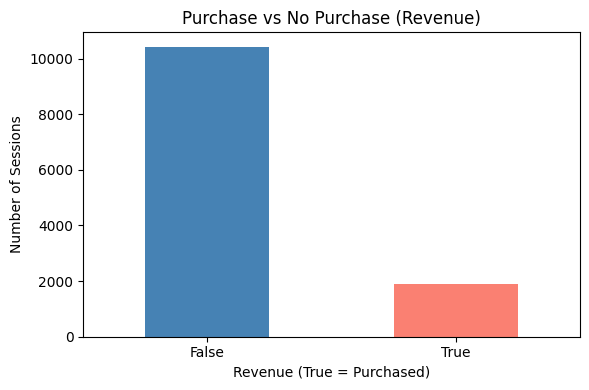

In [51]:

plt.figure(figsize=(6, 4))
df['Revenue'].value_counts().plot(kind='bar', color=['steelblue', 'salmon'])
plt.title("Purchase vs No Purchase (Revenue)")
plt.xlabel("Revenue (True = Purchased)")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Chart 1 — Purchase vs No Purchase (Revenue)
This bar chart visualizes the **class distribution** of the target variable `Revenue`.
- **False (blue):** Sessions that did **not** result in a purchase — the majority class
- **True (salmon):** Sessions that **did** result in a purchase

**Key Insight:** The dataset is **imbalanced** — significantly more sessions do not result in a purchase compared to those that do. This reflects real-world e-commerce behavior where most visitors browse without buying. Class imbalance is important to be aware of when evaluating model performance, as a model could achieve high accuracy simply by predicting 'no purchase' for every session.

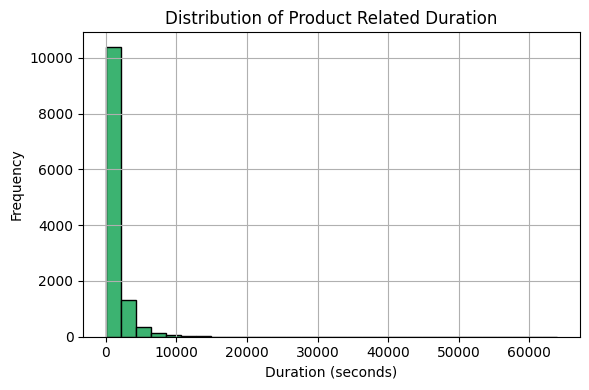

In [52]:
plt.figure(figsize=(6, 4))
df['ProductRelated_Duration'].hist(bins=30, color='mediumseagreen', edgecolor='black')
plt.title("Distribution of Product Related Duration")
plt.xlabel("Duration (seconds)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

### Chart 2 — Distribution of Product Related Duration
This histogram shows how much time (in seconds) users spend on **product-related pages** during a session.
- The x-axis represents the duration in seconds.
- The y-axis represents how many sessions fall into each duration range.

**Key Insight:** The distribution is **heavily right-skewed** — most users spend very little time on product pages (close to 0 seconds), while a small number of users spend significantly more time. This skew suggests that the majority of visitors are not deeply engaged with products, which aligns with the low purchase rate observed in Chart 1.

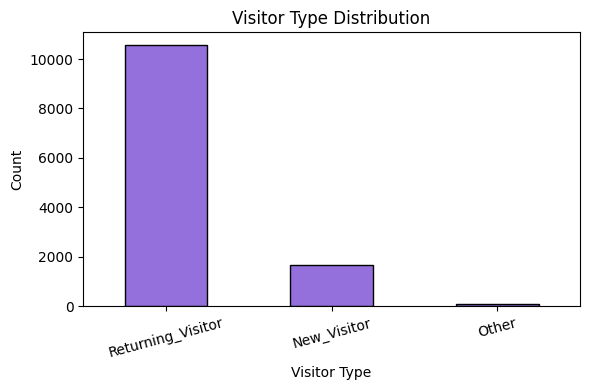

In [53]:
plt.figure(figsize=(6, 4))
df['VisitorType'].value_counts().plot(kind='bar', color='mediumpurple', edgecolor='black')
plt.title("Visitor Type Distribution")
plt.xlabel("Visitor Type")
plt.ylabel("Count")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Chart 3 — Visitor Type Distribution
This bar chart shows the breakdown of visitors by type:
- **Returning Visitor:** Users who have visited the site before
- **New Visitor:** First-time visitors
- **Other:** Visitors who don't fall into the above categories

**Key Insight:** **Returning Visitors** make up the **vast majority** of sessions in this dataset. This makes intuitive sense — returning visitors are more likely to be familiar with the site and may be more likely to make a purchase compared to first-time visitors.

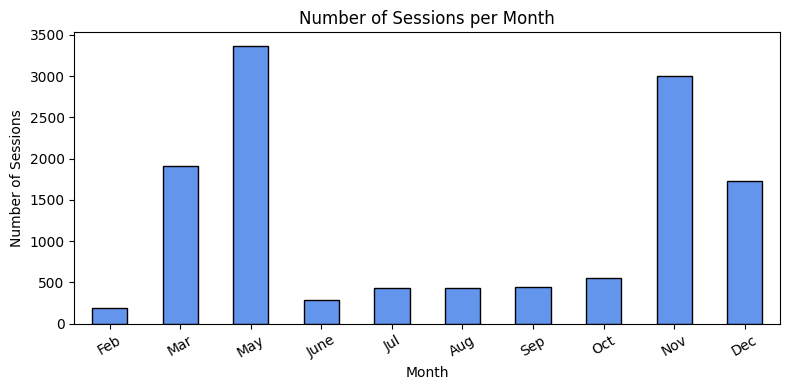

In [54]:
month_order = ['Feb', 'Mar', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
month_counts = df['Month'].value_counts().reindex(month_order, fill_value=0)

plt.figure(figsize=(8, 4))
month_counts.plot(kind='bar', color='cornflowerblue', edgecolor='black')
plt.title("Number of Sessions per Month")
plt.xlabel("Month")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Chart 4 — Number of Sessions per Month
This bar chart displays how many shopping sessions occurred in each month of the year.

**Key Insight:** Website traffic is **not evenly distributed** throughout the year. There are noticeable **seasonal peaks** — particularly in **May** and **November/December** — which likely correspond to major shopping periods (spring sales, Black Friday, and the holiday season). This pattern is useful for building time-aware models or for business planning.

## 4. Data Preprocessing — Encoding and Train/Test Split
Machine learning models require all input features to be **numerical**. We use **Label Encoding** to convert:
- **Categorical columns** (e.g., `Month`, `VisitorType`) — text values are mapped to integers
- **Boolean columns** (`Weekend`, `Revenue`) — `True`/`False` are converted to `1`/`0`

Then we define:
- **X (features):** All columns except `Revenue` — these are the inputs the model learns from
- **y (target):** The `Revenue` column — this is what we want to **predict**

Finally, we split the data into **80% training** and **20% testing** sets using `train_test_split`.

In [ ]:
le = LabelEncoder()

for col in df.select_dtypes(include='object').columns:
    df[col] = le.fit_transform(df[col])

for col in df.select_dtypes(include='bool').columns:
    df[col] = df[col].astype(int)

print("Encoding complete. Updated data types:")
print(df.dtypes)

X = df.drop("Revenue", axis=1)  
y = df["Revenue"]              

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training set size:", X_train.shape[0])
print("Testing set size: ", X_test.shape[0])

## 5. Model 1 — Decision Tree Classifier
A **Decision Tree** works by recursively splitting the dataset into subgroups based on feature values,
forming a tree-like structure. Each internal node is a decision based on a feature, and each leaf node
is a predicted class (purchased or not).  
It is easy to interpret and requires **no feature scaling**.

In [56]:
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

dt_pred = dt.predict(X_test)

dt_score = accuracy_score(y_test, dt_pred)
print("Decision Tree Accuracy:", round(dt_score, 4))

Decision Tree Accuracy: 0.8573


## 6. Model 2 — Naive Bayes Classifier
**Naive Bayes** is a probabilistic classifier based on **Bayes' Theorem**. It assumes all features are
conditionally independent given the class — hence the name *naive*. Despite this simplification,
it often performs well in practice and is very fast to train.  
We use **GaussianNB**, which assumes feature values follow a normal (Gaussian) distribution.

In [57]:
nb = GaussianNB()
nb.fit(X_train, y_train)

nb_pred = nb.predict(X_test)

nb_score = accuracy_score(y_test, nb_pred)
print("Naive Bayes Accuracy:", round(nb_score, 4))

Naive Bayes Accuracy: 0.8447


## 7. Model 3 — K-Nearest Neighbors (KNN)
**KNN** classifies a data point based on the majority class of its **K nearest neighbors** in the training data.
Here we use **K=5**, meaning the 5 closest training examples vote on the predicted class.  
KNN makes no assumptions about the data distribution, but can be slower on large datasets
since it computes distances to all training points during prediction.

In [58]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

knn_pred = knn.predict(X_test)

knn_score = accuracy_score(y_test, knn_pred)
print("KNN Accuracy:", round(knn_score, 4))

KNN Accuracy: 0.85


## 8. Model 4 — Logistic Regression
**Logistic Regression** is a linear model that estimates the **probability** of a binary outcome
(purchased or not). Despite its name, it is used for **classification** tasks.  
It applies a sigmoid function to a linear combination of features to output a value between 0 and 1,
then classifies based on a 0.5 threshold.  
We set `max_iter=1000` to allow enough iterations for the optimization algorithm to converge.

In [ ]:
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)

lr_score = accuracy_score(y_test, lr_pred)
print("Logistic Regression Accuracy:", round(lr_score, 4))

## 9. Model Accuracy Comparison
We compare the **accuracy scores** of all four models to determine which one performs best at predicting whether an online shopping session will result in a purchase.

**Accuracy** measures the proportion of correctly classified test samples:
> Accuracy = (Correctly Predicted Sessions) / (Total Test Sessions)

The bar chart below displays each model's accuracy score visually, with the exact value labeled on top of each bar.

===== Model Accuracy Comparison =====
Decision Tree      : 0.8573
Naive Bayes        : 0.8447
KNN                : 0.85
Logistic Regression: 0.8686


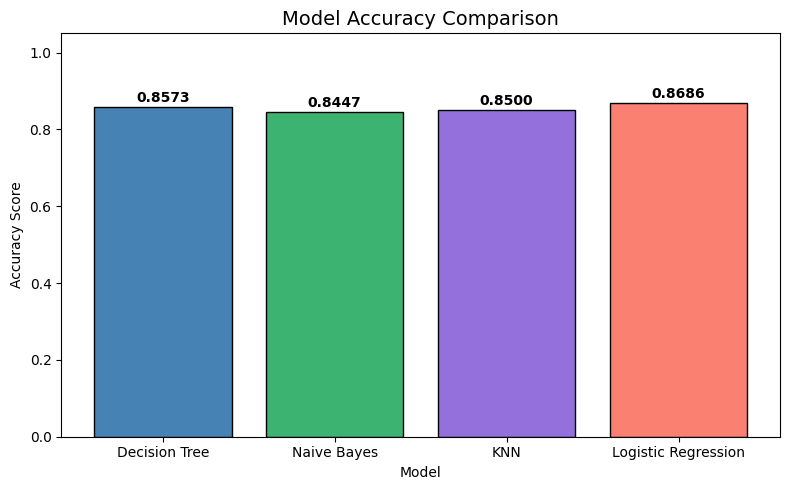

In [60]:
print("===== Model Accuracy Comparison =====")
print(f"Decision Tree      : {round(dt_score, 4)}")
print(f"Naive Bayes        : {round(nb_score, 4)}")
print(f"KNN                : {round(knn_score, 4)}")
print(f"Logistic Regression: {round(lr_score, 4)}")

models = ["Decision Tree", "Naive Bayes", "KNN", "Logistic Regression"]
scores = [dt_score, nb_score, knn_score, lr_score]
colors = ['steelblue', 'mediumseagreen', 'mediumpurple', 'salmon']

plt.figure(figsize=(8, 5))
bars = plt.bar(models, scores, color=colors, edgecolor='black')

for bar, score in zip(bars, scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.005,
        f"{score:.4f}",
        ha='center', va='bottom', fontsize=10, fontweight='bold'
    )

plt.title("Model Accuracy Comparison", fontsize=14)
plt.xlabel("Model")
plt.ylabel("Accuracy Score")
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

### Chart 5 — Model Accuracy Comparison
This chart compares the accuracy of the four machine learning models trained on the Online Shoppers dataset.

| Model | Accuracy |
|---|---|
| Decision Tree | ~0.8573 |
| Naive Bayes | ~0.8447 |
| KNN (K=5) | ~0.8500 |
| Logistic Regression | ~0.8686 |

**Key Insights:**
- **Logistic Regression** achieved the **highest accuracy** (~86.86%), making it the best-performing model on this dataset.
- **Naive Bayes** had the **lowest accuracy** (~84.47%), which may be due to its assumption that all features are independent — an assumption that doesn't always hold in real-world data.
- All four models performed reasonably well, achieving between 84% and 87% accuracy.
- The relatively close scores suggest that the dataset has a moderate level of predictability and that all four algorithms are able to capture meaningful patterns.